# Coalitions between groups

Roadmap step 2, part 2. No group holds a majority alone, so which groups vote together, and who ends up on the winning side?

Each group's **line** on a roll call is its most common position among For, Against and Abstention, counting only groups with at least 5 active members and no tie. Non-attached members have no line and are left out.

- **Line agreement** between two groups is the share of contested roll calls on which both had a line and the lines were the same.
- The **winning side** is For when For outnumbers Against and Against otherwise, with abstentions counting for neither. A group whose line is to abstain is never on the winning side.
- A **winning coalition** is the set of groups whose line matched the winning side.

Contested roll calls follow the USA rule (the smaller of For and Against at least 2.5%). Results at 0% and 10%, and with abstention counted against, are in the sensitivity section.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from howtheyvote import load_rollcalls, load_votes

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1 to 3
NEUTRAL = "#52514e"
MUTED = "#c9c8c1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

TERMS = [9, 10]
CUTOFFS = [0.0, 0.025, 0.10]
# Display order: group means on the first dimension of the agreement maps (notebook 03), the same in both terms.
# Non-attached members aren't a group and come last.
GROUP_ORDER = ["GREEN_EFA", "GUE_NGL", "SD", "RENEW", "EPP", "ECR", "ID", "PFE", "ESN", "NI"]
LABELS = {"GUE_NGL": "The Left", "GREEN_EFA": "Greens/EFA", "SD": "S&D", "RENEW": "Renew", "EPP": "EPP",
          "ECR": "ECR", "ID": "ID", "PFE": "PfE", "ESN": "ESN", "NI": "Non-attached"}
BREXIT = pd.Timestamp("2020-01-31")
TERM_10_START = pd.Timestamp("2024-07-16")


def half_year(dates):
    """Half-years as numbers: 2019.5 is July to December 2019, 2020.0 January to June 2020."""
    return dates.dt.year + (dates.dt.month > 6) * 0.5


def half_label(value):
    return f"{int(value)} {'H2' if value % 1 else 'H1'}"


rollcalls = load_rollcalls()
rollcalls = rollcalls[~rollcalls["is_secret"]].set_index("vote_id")
rollcalls["half"] = half_year(rollcalls["date"])

from clustering import NON_ATTACHED, group_counts, group_line, line_agreement, winning_side

rollcalls["winner"] = winning_side(rollcalls)
recorded = rollcalls.dropna(subset=["result"])
check = pd.crosstab(recorded["winner"].fillna("tie"), recorded["result"])
print("Winning side from positions against the export's recorded result:")
display(check)

frames, sizes, vote_frames = [], {}, []
for term in TERMS:
    votes = load_votes(term)
    # Members listed per roll call, with any position including Did not vote: the group's size on that day.
    sizes[term] = votes.groupby(["vote_id", "group_code"], observed=True).size().unstack().mean()
    counts = group_counts(votes)
    vote_frames.append(counts.reset_index())
    counts = counts[counts.index.get_level_values("group_code") != NON_ATTACHED]
    frames.append(group_line(counts).rename("line").reset_index().assign(term=term))
lines = pd.concat(frames, ignore_index=True)
group_votes = pd.concat(vote_frames, ignore_index=True)
group_votes["group_code"] = group_votes["group_code"].astype(str)
lines["group_code"] = lines["group_code"].astype(str)
lines = lines.join(rollcalls[["winner", "half", "vote_part", "minority_share", "minority_share_with_abstention"]],
                   on="vote_id")
contested = lines[lines["minority_share"] >= 0.025]
print(f"{contested['vote_id'].nunique():,} contested roll calls")

Winning side from positions against the export's recorded result:


result,ADOPTED,REJECTED
winner,,
AGAINST,0,4380
FOR,3702,12
tie,1,2


24,162 contested roll calls


The export records an outcome for only 8,097 of the 25,686 open roll calls. On those, the side with more For or Against votes matches the recorded outcome on 8,082. Of the rest, 12 had more For than Against but were rejected, probably because they needed a majority of all members, and 3 were ties. So the winning side is taken from positions on every roll call.

## Which groups vote together

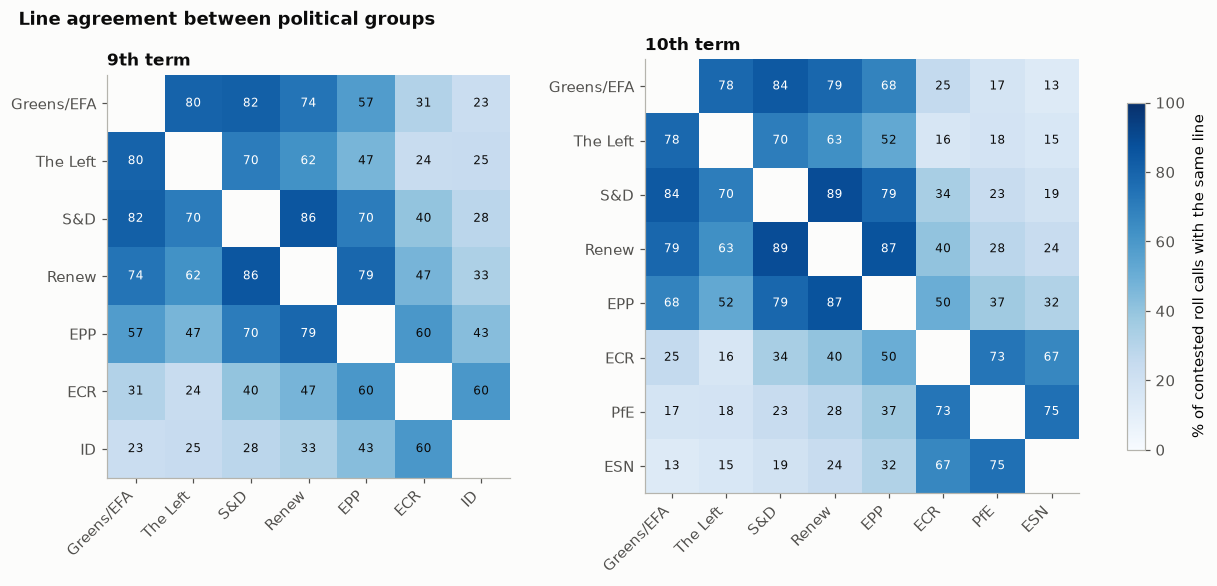

9th term, % of contested roll calls with the same line:


,Greens/EFA,The Left,S&D,Renew,EPP,ECR,ID
Greens/EFA,100.0,80.5,81.6,73.7,57.4,31.0,22.9
The Left,80.5,100.0,70.4,62.2,46.7,24.2,24.6
S&D,81.6,70.4,100.0,85.5,70.5,40.1,28.4
Renew,73.7,62.2,85.5,100.0,78.7,47.2,32.8
EPP,57.4,46.7,70.5,78.7,100.0,59.8,43.3
ECR,31.0,24.2,40.1,47.2,59.8,100.0,59.8
ID,22.9,24.6,28.4,32.8,43.3,59.8,100.0


10th term, % of contested roll calls with the same line:


,Greens/EFA,The Left,S&D,Renew,EPP,ECR,PfE,ESN
Greens/EFA,100.0,78.3,84.4,78.6,67.6,25.5,17.4,13.1
The Left,78.3,100.0,69.9,63.0,52.4,16.4,18.0,15.5
S&D,84.4,69.9,100.0,88.9,78.6,34.0,23.5,19.0
Renew,78.6,63.0,88.9,100.0,86.7,40.5,28.4,23.8
EPP,67.6,52.4,78.6,86.7,100.0,50.3,36.9,31.6
ECR,25.5,16.4,34.0,40.5,50.3,100.0,73.2,66.7
PfE,17.4,18.0,23.5,28.4,36.9,73.2,100.0,75.1
ESN,13.1,15.5,19.0,23.8,31.6,66.7,75.1,100.0


In [2]:
def agreement_table(frame, term):
    data = frame[frame["term"] == term].set_index(["vote_id", "group_code"])["line"]
    table = line_agreement(data)
    order = [g for g in GROUP_ORDER if g in table.index]
    return table.loc[order, order]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [7, 8]}, layout="constrained")
for axis, term in zip(axes, TERMS):
    table = agreement_table(contested, term)
    shown = table.where(~np.eye(len(table), dtype=bool))
    image = axis.imshow(shown * 100, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(table)):
        for j in range(len(table)):
            if i != j:
                value = table.iloc[i, j] * 100
                axis.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8,
                          color="white" if value >= 60 else "#0b0b0b")
    names = [LABELS[g] for g in table.index]
    axis.set_xticks(range(len(names)), names, rotation=45, ha="right")
    axis.set_yticks(range(len(names)), names)
    axis.grid(False)
    axis.set_title(f"{term}th term")
fig.colorbar(image, ax=axes, shrink=0.8, label="% of contested roll calls with the same line")
fig.suptitle("Line agreement between political groups", x=0.01, ha="left", fontweight="bold")
plt.show()
for term in TERMS:
    print(f"{term}th term, % of contested roll calls with the same line:")
    display((agreement_table(contested, term) * 100).round(1).rename(index=LABELS, columns=LABELS))

**What this shows**

- **Agreement falls with distance in the ordering** used throughout these notebooks, from Greens/EFA to ESN. Neighbours agree on 50% to 89% of contested roll calls, and the groups at the two ends on 13% to 25%.
- **The closest pair in both terms is S&D and Renew** (85.5% and 88.9%).
- **In the 10th term the EPP agreed more with S&D (70.5% to 78.6%) and Renew (78.7% to 86.7%), and less with ECR (59.8% to 50.3%).**
- **The three groups to the right of the EPP agree with each other on 67% to 75%** in the 10th term. ECR and ID agreed on 60% in the 9th.

The two terms vote on different roll calls. Group membership also changed: the 2024 election, members moving between groups, and the UK's departure in the 9th term. So a difference between terms describes the groups' recorded votes, not the same members changing their minds.

## Who is on the winning side

In [3]:
decided = contested.dropna(subset=["winner"]).copy()
decided["won"] = decided["line"].eq(decided["winner"])
has_line = decided.dropna(subset=["line"])
winning = has_line.groupby(["group_code", "term"])["won"].mean().unstack()
final = has_line[has_line["vote_part"] == "final"].groupby(["group_code", "term"])["won"].mean().unstack()
winning = pd.concat({"contested roll calls": winning, "final votes only": final}, axis=1)
winning = winning.reindex([g for g in GROUP_ORDER if g in winning.index]).rename(index=LABELS)
display((winning * 100).round(1))

contested roll calls       final votes only      
term                         9     10               9     10
group_code                                                  
Greens/EFA                 74.5  73.3             85.6  80.1
The Left                   63.0  58.3             68.4  50.2
S&D                        87.7  84.1             96.6  91.5
Renew                      92.8  90.5             97.6  92.7
EPP                        82.4  93.6             90.3  92.8
ECR                        50.2  48.7             60.7  70.5
ID                         36.2   NaN             29.5   NaN
PfE                         NaN  36.6              NaN  41.8
ESN                         NaN  30.4              NaN  26.0

**Renew is on the winning side most often** (93% and 91% of contested roll calls), then S&D and the EPP. **The EPP's share rose the most, from 82% to 94%.** The Left and ECR are on the winning side about half the time or a bit more, and ID, PfE and ESN about a third. On final votes the centre groups win 90% or more.

In [4]:
coalitions = decided[decided["won"]].groupby("vote_id")["group_code"].apply(
    lambda s: " + ".join(LABELS[g] for g in GROUP_ORDER if g in set(s)))
coalitions = coalitions.to_frame("coalition").join(rollcalls["term"])
for term in TERMS:
    shares = coalitions[coalitions["term"] == term]["coalition"].value_counts(normalize=True)
    print(f"{term}th term: {len(shares)} different winning coalitions; the 8 most common:")
    with pd.option_context("display.max_colwidth", None):
        display((shares.head(8) * 100).round(1).rename("% of contested roll calls").to_frame())

9th term: 98 different winning coalitions; the 8 most common:


,% of contested roll calls
coalition,
Greens/EFA + The Left + S&D + Renew + EPP,23.4
Greens/EFA + The Left + S&D + Renew,11.4
Greens/EFA + The Left + S&D + Renew + EPP + ECR,9.9
S&D + Renew + EPP + ECR + ID,6.7
Renew + EPP + ECR + ID,5.2
Greens/EFA + The Left + S&D + Renew + EPP + ECR + ID,5.0
Greens/EFA + S&D + Renew + EPP + ECR,4.9
Greens/EFA + S&D + Renew + EPP + ECR + ID,4.3


10th term: 146 different winning coalitions; the 8 most common:


,% of contested roll calls
coalition,
Greens/EFA + The Left + S&D + Renew + EPP,36.9
S&D + Renew + EPP + ECR + PfE + ESN,6.4
Greens/EFA + The Left + S&D + Renew + EPP + ECR,5.9
EPP + ECR + PfE + ESN,5.8
Greens/EFA + S&D + Renew + EPP + ECR,5.1
Renew + EPP + ECR + PfE + ESN,4.9
Greens/EFA + S&D + Renew + EPP,3.1
Greens/EFA + The Left + S&D + Renew + EPP + ECR + PfE,3.1


In [5]:
CENTRE_LEFT = {"GUE_NGL", "GREEN_EFA", "SD", "RENEW"}
members_won = decided[decided["won"]].groupby("vote_id")["group_code"].agg(set).to_frame("groups").join(rollcalls["term"])
members_won["kind"] = np.select(
    [members_won["groups"].map(lambda g: "EPP" in g and not (g & CENTRE_LEFT)),
     members_won["groups"].map(lambda g: "EPP" not in g)],
    ["EPP without any group to its left", "without the EPP"], "EPP with a group to its left")
display((pd.crosstab(members_won["kind"], members_won["term"], normalize="columns") * 100).round(1))

table = pd.DataFrame(sizes).reindex([g for g in GROUP_ORDER if g in pd.DataFrame(sizes).index])
table.loc["all members"] = table.sum()
table.loc["EPP + ECR + ID or PfE + ESN"] = table.loc[["EPP", "ECR", "ID", "PFE", "ESN"]].sum()
table.loc["half of all members"] = table.loc["all members"] / 2
print("Mean members listed per roll call, by group (from the data):")
display(table.rename(index=LABELS).round(0))

term,9,10
kind,,
EPP with a group to its left,80.5,87.0
EPP without any group to its left,1.9,6.7
without the EPP,17.6,6.4


Mean members listed per roll call, by group (from the data):


,9,10
group_code,,
Greens/EFA,71.0,53.0
The Left,39.0,46.0
S&D,145.0,136.0
Renew,100.0,76.0
EPP,180.0,187.0
ECR,64.0,80.0
ID,69.0,NaN
PfE,NaN,85.0
ESN,NaN,27.0


**What this shows**

- **The most common winning coalition is every group from Greens/EFA to the EPP** (23% of contested roll calls in the 9th term, 37% in the 10th). The groups to the right of the EPP are on the losing side.
- **Winning without the EPP became rare.** A majority without the EPP won 17.6% of contested roll calls in the 9th term, mostly the four groups to its left together (11.4%). In the 10th term it won 6.4%.
- **Winning with no group to the left of the EPP became more common:** 1.9% of contested roll calls in the 9th term, 6.7% in the 10th, mostly the EPP with ECR, PfE and ESN.
- **Group sizes are consistent with this.** In the data, the EPP, ECR and ID averaged 313 members listed per roll call in the 9th term, below half of all members (353). In the 10th, the EPP, ECR, PfE and ESN average 379, above half (359). Votes need a majority of votes cast, not of members, so the next section counts votes cast directly.

## The EPP between S&D–Renew and the ECR pair

On many roll calls S&D and Renew take one line together, and ECR with its nearest neighbour (ID in the 9th term, PfE in the 10th) takes the other. These are the closest pairs on each side of the EPP in the heatmap above. The names below are the groups', not a claim about ideology. On those roll calls, which side does the EPP take, and which side wins?

A roll call counts as split when both pairs have a line and the lines differ. A line can be to abstain, and an abstaining side can't win, so the main results use only splits of For against Against.

In [6]:
SIDE_A = "S&D–Renew"
SIDE_B = "ECR pair"


def split_rollcalls(frame, for_against_only=False):
    wide = frame.pivot(index="vote_id", columns="group_code", values="line")
    wide = wide.join(rollcalls[["term", "half", "winner", "vote_part"]])
    partner = pd.Series(np.where(wide["term"] == 9, wide["ID"], wide["PFE"]), index=wide.index)
    wide["side_a"] = wide["SD"].where(wide["SD"] == wide["RENEW"])
    wide["side_b"] = wide["ECR"].where(wide["ECR"] == partner)
    split = wide.dropna(subset=["side_a", "side_b", "EPP"])
    split = split[split["side_a"] != split["side_b"]].copy()
    if for_against_only:
        split = split[split["side_a"].isin(["FOR", "AGAINST"]) & split["side_b"].isin(["FOR", "AGAINST"])]
    split["epp_side"] = np.select([split["EPP"] == split["side_a"], split["EPP"] == split["side_b"]],
                                  [f"with {SIDE_A}", f"with {SIDE_B}"], "neither")
    split["b_won"] = split["side_b"] == split["winner"]
    return split


def split_summary(split):
    return split.groupby("term").agg(
        rollcalls=("EPP", "size"),
        epp_with_b=("epp_side", lambda s: s.eq(f"with {SIDE_B}").mean()),
        epp_with_a=("epp_side", lambda s: s.eq(f"with {SIDE_A}").mean()),
        b_won=("b_won", "mean"),
    )


split = split_rollcalls(contested)
summary = split_summary(split)
summary["share_of_contested"] = summary["rollcalls"] / contested.groupby("term")["vote_id"].nunique()
print("All splits, including abstention lines:")
display(summary.round(3))
abstaining = pd.DataFrame({
    f"{SIDE_A} abstains": split["side_a"].eq("ABSTENTION"),
    f"{SIDE_B} abstains": split["side_b"].eq("ABSTENTION"),
    "EPP abstains": split["EPP"].eq("ABSTENTION"),
}).groupby(split["term"]).mean()
print("Share of those splits with an abstention line:")
display(abstaining.round(3))
strict = split_rollcalls(contested, for_against_only=True)
print("Only For against Against splits (used from here on):")
display(split_summary(strict).round(3))
print("Who won, by the EPP's side:")
display(pd.crosstab([strict["term"], strict["epp_side"]],
                    strict["b_won"].map({True: f"{SIDE_B} won", False: f"{SIDE_B} lost"}), normalize="index").round(3))

All splits, including abstention lines:


,rollcalls,epp_with_b,epp_with_a,b_won,share_of_contested
term,,,,,
9,5851,0.342,0.642,0.062,0.326
10,2884,0.184,0.805,0.137,0.463


Share of those splits with an abstention line:


,S&D–Renew abstains,ECR pair abstains,EPP abstains
term,,,
9,0.001,0.040,0.011
10,0.000,0.021,0.007


Only For against Against splits (used from here on):


,rollcalls,epp_with_b,epp_with_a,b_won
term,,,,
9,5607,0.354,0.636,0.063
10,2821,0.188,0.804,0.140


Who won, by the EPP's side:


b_won                ECR pair lost  ECR pair won
term epp_side                                   
9    neither                 1.000         0.000
     with ECR pair           0.823         0.177
     with S&D–Renew          0.999         0.001
10   neither                 1.000         0.000
     with ECR pair           0.269         0.731
     with S&D–Renew          0.997         0.003

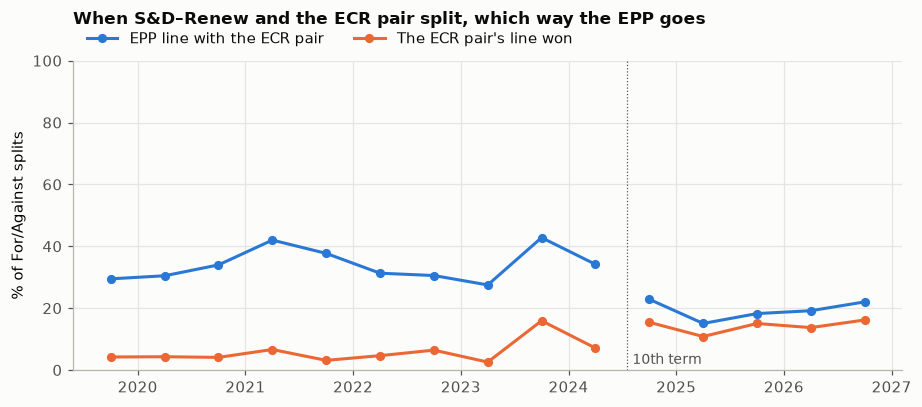

,half,rollcalls,epp_with_b,b_won
0,2019 H2,190,0.295,0.042
1,2020 H1,256,0.305,0.043
2,2020 H2,930,0.340,0.041
3,2021 H1,950,0.420,0.066
4,2021 H2,480,0.377,0.031
5,2022 H1,818,0.313,0.046
6,2022 H2,311,0.305,0.064
7,2023 H1,429,0.275,0.026
8,2023 H2,722,0.428,0.159
9,2024 H1,521,0.342,0.071


In [7]:
by_half = strict.groupby("half").agg(
    rollcalls=("EPP", "size"),
    epp_with_b=("epp_side", lambda s: s.eq(f"with {SIDE_B}").mean()),
    b_won=("b_won", "mean"),
).reset_index()
fig, axis = plt.subplots(figsize=(8.5, 3.8))
# Lines break between terms: the ECR pair is ECR with ID in the 9th term and ECR with PfE in the 10th.
for term_halves, first in [(by_half["half"] < 2024.5, True), (by_half["half"] >= 2024.5, False)]:
    data = by_half[term_halves]
    axis.plot(data["half"] + 0.25, data["epp_with_b"] * 100, color=SERIES[0], marker="o", markersize=5,
              label=f"EPP line with the {SIDE_B}" if first else None)
    axis.plot(data["half"] + 0.25, data["b_won"] * 100, color=SERIES[1], marker="o", markersize=5,
              label=f"The {SIDE_B}'s line won" if first else None)
axis.axvline(TERM_10_START.year + TERM_10_START.day_of_year / 365, color=NEUTRAL, linewidth=0.8, linestyle=":")
axis.text(TERM_10_START.year + TERM_10_START.day_of_year / 365 + 0.05, 2, "10th term", color=NEUTRAL, fontsize=9)
axis.set_ylim(0, 100)
axis.set_ylabel(f"% of For/Against splits")
axis.set_title(f"When {SIDE_A} and the {SIDE_B} split, which way the EPP goes", pad=24)
axis.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
fig.tight_layout()
plt.show()
display(by_half.assign(half=by_half["half"].map(half_label)).round(3))

**What this shows**

- **Abstention lines hardly matter here.** Of all splits, 4.0% (9th term) and 2.1% (10th) have the ECR pair abstaining. Keeping only For against Against splits leaves 5,607 and 2,821 roll calls, 31% and 45% of contested ones, and changes the shares below by under 0.02.
- **The EPP sides with S&D–Renew on most splits,** 64% in the 9th term and 80% in the 10th. It sides with the ECR pair less often in the 10th term (19%, against 35%).
- **But when it sides with the ECR pair, that side now usually wins:** 73% of those roll calls in the 10th term, against 18% in the 9th. When the EPP sides with S&D–Renew, the ECR pair loses almost every time in both terms (99.7% or more).
- **So the ECR pair's line won more often in the 10th term (14.0% of splits, against 6.3%)** even though the EPP joined it less often.
- **By half-year,** the ECR pair won 2.6% to 7.1% of splits in every half-year of the 9th term except the second half of 2023 (15.9%), when the EPP also joined it most often (42.8%). In every half-year of the 10th term it won 10.8% to 16.2%.

These are counts of roll calls, which the groups request and partly choose. A group expecting to win may request more of them, so the shares describe recorded votes, not every decision.

### Were the EPP and the groups to its right enough on their own?

On For against Against splits where the EPP sided with the ECR pair, add up the votes cast on that side by EPP, ECR, ID or PfE, and ESN members. If they outnumber all votes cast on the other side, these groups could win without any vote from Renew, S&D, The Left, Greens/EFA or non-attached members. Also shown: whether ESN took the same line.

In [8]:
with_b = strict[strict["epp_side"] == f"with {SIDE_B}"].copy()
bloc_groups = ["EPP", "ECR", "ID", "PFE", "ESN"]
positions = group_votes[group_votes["vote_id"].isin(with_b.index) & group_votes["group_code"].isin(bloc_groups)]
positions = positions.join(with_b["side_b"].str.lower().rename("line"), on="vote_id")
positions["on_line"] = np.where(positions["line"] == "for", positions["for"], positions["against"])
with_b["bloc_votes"] = positions.groupby("vote_id")["on_line"].sum().reindex(with_b.index).fillna(0)
other = rollcalls.loc[with_b.index]
with_b["other_side_votes"] = np.where(with_b["side_b"] == "FOR", other["n_against"], other["n_for"])
with_b["bloc_enough"] = with_b["bloc_votes"] > with_b["other_side_votes"]
display(pd.crosstab([with_b["term"], with_b["bloc_enough"].map({True: "bloc alone enough", False: "bloc alone short"})],
                    with_b["b_won"].map({True: "won", False: "lost"})))
esn = with_b[with_b["term"] == 10]
print("ESN's line on these roll calls in the 10th term:")
esn_line = pd.Series(np.select([esn["ESN"] == esn["side_b"], esn["ESN"].isna()],
                               ["same as the ECR pair", "no line"], "different"), index=esn.index)
display(pd.crosstab(esn_line, esn["b_won"].map({True: "won", False: "lost"}), margins=True))

b_won                   lost  won
term bloc_enough                 
9    bloc alone enough     0   73
     bloc alone short   1635  278
10   bloc alone enough     0  348
     bloc alone short    143   40

ESN's line on these roll calls in the 10th term:


b_won,lost,won,All
row_0,,,
different,25,30,55
no line,1,1,2
same as the ECR pair,117,357,474
All,143,388,531


**What this shows**

- **In the 10th term, the EPP and the groups to its right usually had the votes on their own.** On 348 of the 531 splits where the EPP sided with the ECR pair (66%), their own votes outnumbered everything cast on the other side, and they won all 348. On the other 183 they won 40 times, with votes from other groups or members.
- **In the 9th term this almost never happened:** 73 of 1,986 (3.7%). They won those 73, and 278 of the 1,913 where they needed other votes.
- **ESN took the same line as the ECR pair on 474 of the 531** 10th-term roll calls.
- So the higher win rate in the 10th term goes with the EPP and the groups to its right casting more votes than the other side, which they rarely did in the 9th.

This counts votes, so it shows how the wins came about arithmetically. It doesn't say why groups voted as they did, or why these roll calls were requested.

The second half of 2023 shows that a high win rate also occurred in the 9th term (15.9%), so the arithmetic in the 10th term isn't the only way it can happen.

In [9]:
by_part = strict[strict["vote_part"].isin(["final", "amendment", "text part"])].groupby(["term", "vote_part"]).agg(
    rollcalls=("EPP", "size"),
    epp_with_b=("epp_side", lambda s: s.eq(f"with {SIDE_B}").mean()),
    b_won=("b_won", "mean"),
)
display(by_part.round(3))

rollcalls  epp_with_b  b_won
term vote_part                              
9    amendment       3303       0.365  0.094
     final            264       0.197  0.030
     text part       1914       0.359  0.020
10   amendment       1995       0.164  0.139
     final            105       0.200  0.171
     text part        665       0.259  0.138

**The change shows on every kind of roll call.** In the 10th term the ECR pair won 13.8% to 17.1% of split final votes, amendments and text parts. In the 9th term it won 9.4% of split amendments but only 3.0% of final votes and 2.0% of text parts. Final votes are few (105 split ones in the 10th term), so that figure is less precise.

## Sensitivity

The main numbers at other cutoffs for contested roll calls, and with abstention counted against when deciding which roll calls are contested.

In [10]:
def epp_summary(frame):
    result = split_summary(split_rollcalls(frame, for_against_only=True))
    return result.rename(columns={"epp_with_b": "epp_with_ecr_pair", "b_won": "ecr_pair_won"})[
        ["rollcalls", "epp_with_ecr_pair", "ecr_pair_won"]]

rows = {}
for label, frame in [
    ("all roll calls", lines),
    ("contested (2.5%)", contested),
    ("contested (10%)", lines[lines["minority_share"] >= 0.10]),
    ("contested, abstention against (2.5%)", lines[lines["minority_share_with_abstention"] >= 0.025]),
]:
    result = epp_summary(frame)
    agreement = {term: agreement_table(frame, term) for term in TERMS}
    for term in TERMS:
        rows[(label, term)] = {
            **result.loc[term].to_dict(),
            "EPP-S&D agreement": agreement[term].loc["EPP", "SD"],
            "EPP-ECR agreement": agreement[term].loc["EPP", "ECR"],
            "S&D-Renew agreement": agreement[term].loc["SD", "RENEW"],
        }
display(pd.DataFrame(rows).T.round(3))

rollcalls  epp_with_ecr_pair  \
all roll calls                       9      5607.0              0.354   
                                     10     2821.0              0.188   
contested (2.5%)                     9      5607.0              0.354   
                                     10     2821.0              0.188   
contested (10%)                      9      5607.0              0.354   
                                     10     2821.0              0.188   
contested, abstention against (2.5%) 9      5607.0              0.354   
                                     10     2821.0              0.188   

                                         ecr_pair_won  EPP-S&D agreement  \
all roll calls                       9          0.063              0.725   
                                     10         0.140              0.792   
contested (2.5%)                     9          0.063              0.705   
                                     10         0.140              0.786   
contested (10%)                      9          0.063              0.644   
                                     10         0.140              0.771   
contested, abstention against (2.5%) 9          0.063              0.719   
                                     10         0.140              0.791   

                                         EPP-ECR agreement  \
all roll calls                       9               0.622   
                                     10              0.517   
contested (2.5%)                     9               0.598   
                                     10              0.503   
contested (10%)                      9               0.548   
                                     10              0.471   
contested, abstention against (2.5%) 9               0.613   
                                     10              0.514   

                                         S&D-Renew agreement  
all roll calls                       9                 0.865  
                                     10                0.892  
contested (2.5%)                     9                 0.855  
                                     10                0.889  
contested (10%)                      9                 0.826  
                                     10                0.881  
contested, abstention against (2.5%) 9                 0.862  
                                     10                0.891

**The results don't depend on the cutoff.** Every For against Against split between S&D–Renew and the ECR pair is contested under all four rules, so the split results are identical. The EPP's higher agreement with S&D and lower agreement with ECR in the 10th term hold at every cutoff and under both abstention rules.

## Summary

- Group agreement falls with distance along one ordering, from Greens/EFA to ESN. The most common winning coalition in both terms is every group from Greens/EFA to the EPP.
- In the 10th term, compared with the 9th, the EPP agreed more with S&D and Renew (70.5% to 78.6% and 78.7% to 86.7%) and less with ECR (59.8% to 50.3%). It was on the winning side more often (82% to 94%).
- When S&D–Renew and the ECR pair split, the EPP sides with S&D–Renew most of the time (64%, then 80%). It joins the ECR pair less often in the 10th term, but that side now usually wins (73%, against 18%).
  - On 66% of those 10th-term roll calls, the EPP and the groups to its right cast more votes than the whole other side, against 3.7% in the 9th term.
- These are descriptions of requested roll calls in two terms with different agendas and members. Results are the same at every cutoff and with abstention counted against.